# 03. Low-volatility gate ablation with price-only events

Holding the learned risk score and the alert budget fixed, I ask whether the low-volatility filter improves warning quality or only excludes crash opportunities. I also ask whether, without the gate, adding the spectral score hS to volatility and sell flow improves event detection.

- I use the one-minute Binance spot BTCUSDT cache of notebook 01 and the price-only crash catalog of notebook 02 (`event_definition_eligibility_audit/price_only_event_catalog.csv`). I fit on 2021, calibrate on 2022 and compare on 2023 to April 2026.
- I compare logistic models on V, V+F, V+H, V+F+H and H+F (V volatility, F taker-sell ratio, H spectral), each with and without the low-volatility gate, under annual alert targets of 60, 120, 240 and 480 (primary 240).
- This analysis is retrospective and exploratory (hypothesis-generating); I have studied the period repeatedly.
- I write the results to `gate_ablation_price_only_v1/`.


## Design

- Crash catalog of notebook 02: a 4% fall from the preceding 240-minute peak, 5 consecutive closes, 24-hour refractory period.
- Primary success: an emitted alert 30–240 minutes before the first 4% breach. Stricter secondary success: the matched alert comes before the first 1% decline.
- Every model uses the same candidate universe (positive volume, finite features). I fit the models on 2021, calibrate alert rates on 2022 scores only and compare them retrospectively on 2023 to April 2026.
- All policies use the same alert scheduler with a 240-minute cooldown and the same monthly maximum. The training fit is identical for the gated and ungated arms; only the alert eligibility gate changes. I calibrate each arm's threshold separately on 2022 to a common alert-rate target, so realized alert counts can still differ, and I report them.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Outside Colab — check local files manually.')

BASE=Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
# --- SPOT guard: this notebook may only read the spot cache built and fingerprint-verified by notebook 1 ---
import json as _json
_src_file = BASE/'cache'/'DATA_SOURCE.json'
if not _src_file.is_file() or _json.loads(_src_file.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Not a spot cache: {_src_file} is missing or venue!=spot. Run notebook 1 (1_..._SPOT) to the end first.')
print('SPOT cache verified:', _json.loads(_src_file.read_text())['market'])

CACHE=BASE/'cache'
CATALOG=BASE/'event_definition_eligibility_audit/price_only_event_catalog.csv'
OUT=BASE/'gate_ablation_price_only_v1'
OUT.mkdir(parents=True, exist_ok=True)
for fp in [CACHE/'BTCUSDT_1m_regularized.parquet', CACHE/'btc_signals_1m.parquet', CATALOG]:
    if not fp.exists(): raise FileNotFoundError(str(fp))

btc=pd.read_parquet(CACHE/'BTCUSDT_1m_regularized.parquet',columns=['close','volume']).sort_index()
sig=pd.read_parquet(CACHE/'btc_signals_1m.parquet',columns=['z_hs','z_vol','tsr','price_lowvol']).sort_index()
for frame in (btc,sig):
    if not isinstance(frame.index,pd.DatetimeIndex) or frame.index.tz is None: raise ValueError('Index must be UTC-aware datetime')
    frame.index=frame.index.tz_convert('UTC')
if not btc.index.equals(sig.index): raise ValueError('Cache timestamps differ; the files cannot be merged')
if not btc.index.is_unique: raise ValueError('Duplicated minute bars')

catalog=pd.read_csv(CATALOG,parse_dates=['peak_utc','onset_1pct_utc','breach_utc','confirmed_utc'])
for c in ['peak_utc','onset_1pct_utc','breach_utc','confirmed_utc']:
    catalog[c]=pd.to_datetime(catalog[c],utc=True)
catalog=catalog.sort_values('breach_utc').reset_index(drop=True)
assert catalog.breach_utc.is_monotonic_increasing and catalog.breach_utc.is_unique
assert (catalog.confirmed_utc>=catalog.breach_utc).all()

vol=btc.volume.to_numpy(dtype=float)
close=btc.close.to_numpy(dtype=float)
H=sig.z_hs.to_numpy(dtype=float); V=sig.z_vol.to_numpy(dtype=float)
F=sig.tsr.to_numpy(dtype=float); G=sig.price_lowvol.to_numpy(dtype=float)
COMMON=np.isfinite(close)&(close>0)&np.isfinite(vol)&(vol>0)&np.isfinite(H)&np.isfinite(V)&np.isfinite(F)&(F>=0)&(F<=1)
LOWVOL=COMMON&(G==1)
print('Cache range:',btc.index[0],btc.index[-1],'bars',len(btc))
print('Common feature-valid:',int(COMMON.sum()),'of',len(COMMON),'Low-vol candidate bars:',int(LOWVOL.sum()))
print('Catalog crashes by year:')
display(catalog.groupby(catalog.breach_utc.dt.year).size().rename('events'))
print('Venue: Binance spot cache.')


Mounted at /content/drive
SPOT cache verified: Binance spot BTCUSDT 1m klines
Cache range: 2020-01-01 00:00:00+00:00 2026-04-30 23:59:00+00:00 bars 3329280
Common feature-valid: 3304648 of 3329280 Low-vol candidate bars: 1106725
Catalog crashes by year:


,events
breach_utc,
2020,42
2021,89
2022,55
2023,17
2024,36
2025,21
2026,9


Venue: Binance spot cache.


## 1. Event-aligned training label

At each bar close *t*, the label is 1 if a catalog 4% breach occurs 30–240 minutes later, without the low-volatility condition. I drop the last 245 minutes of 2021 so that all training labels lie within 2021.

In [2]:
NS=60*10**9
LEAD_MIN=30; LEAD_MAX=240; COOLDOWN=240; CONFIRM=5
TRAIN_START=pd.Timestamp('2021-01-01',tz='UTC')
CAL_START=pd.Timestamp('2022-01-01',tz='UTC')
EVAL_START=pd.Timestamp('2023-01-01',tz='UTC')
EVAL_END=min(pd.Timestamp('2026-05-01',tz='UTC'),btc.index[-1]+pd.Timedelta(minutes=1))
T=btc.index.asi8
BREACH=catalog.breach_utc.astype('int64').to_numpy()

# Inclusive lead bound [30,240] minutes.
next_i=np.searchsorted(BREACH,T+LEAD_MIN*NS,'left')
positive=np.zeros(len(T),dtype=bool)
exists=next_i<len(BREACH)
positive[exists]=(BREACH[next_i[exists]] <= T[exists]+LEAD_MAX*NS)

train_sel=COMMON&(T>=TRAIN_START.value)&(T < (CAL_START-pd.Timedelta(minutes=LEAD_MAX+CONFIRM)).value)
cal_sel=COMMON&(T>=CAL_START.value)&(T<EVAL_START.value)
eval_sel=COMMON&(T>=EVAL_START.value)&(T<EVAL_END.value)
assert positive[train_sel].any() and (~positive[train_sel]).any(), 'Training targets have only one class'
assert train_sel.any() and cal_sel.any() and eval_sel.any()

XALL=np.column_stack([V,F,H]).astype('float64',copy=False)
FEATURES={'V':(0,), 'V+F':(0,1), 'V+H':(0,2), 'V+F+H':(0,1,2), 'H+F':(2,1)}
print('TRAIN',int(train_sel.sum()),'positive minutes',int(positive[train_sel].sum()))
print('CAL',int(cal_sel.sum()),'positive minutes (not used for threshold calibration)',int(positive[cal_sel].sum()))
print('EVAL',int(eval_sel.sum()),'catalog events after start',int(((catalog.breach_utc>=EVAL_START+pd.Timedelta(minutes=LEAD_MAX))&(catalog.breach_utc<EVAL_END)).sum()))

models={}; cal_score={}; eval_score={}
for name,inds in FEATURES.items():
    clf=make_pipeline(StandardScaler(),LogisticRegression(C=0.2, class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
    clf.fit(XALL[train_sel][:,inds],positive[train_sel].astype('int8'))
    models[name]=clf
    cal_score[name]=clf.predict_proba(XALL[cal_sel][:,inds])[:,1]
    eval_score[name]=clf.predict_proba(XALL[eval_sel][:,inds])[:,1]
    print(f'{name}: fitted {int(train_sel.sum()):,} same-universe 2021 bars')


TRAIN 524087 positive minutes 18779
CAL 525600 positive minutes (not used for threshold calibration) 11605
EVAL 1750857 catalog events after start 83
V: fitted 524,087 same-universe 2021 bars
V+F: fitted 524,087 same-universe 2021 bars
V+H: fitted 524,087 same-universe 2021 bars
V+F+H: fitted 524,087 same-universe 2021 bars
H+F: fitted 524,087 same-universe 2021 bars


## 2. Same real-time scheduler for all arms (gate ablation)

An alert can fire only at the current bar close, and `gated` and `ungated` differ only in whether the scheduler enforces the low-volatility gate. I calibrate each policy's fixed score threshold on 2022 scores, with the same monthly cap and cooldown that I use later. The annual targets are requested counts, so I report unattainable targets and calibration errors.

In [3]:
def emit_alerts(t_ns,prob,thresh,eligible,month_code,monthly_cap,cooldown=COOLDOWN):
    """Return strictly time-ordered UTC-nanosecond alert timestamps; no future information."""
    t_ns=np.asarray(t_ns,dtype='int64')
    prob=np.asarray(prob,dtype='float64')
    eligible=np.asarray(eligible,dtype=bool)
    month_code=np.asarray(month_code,dtype='int32')
    assert len(t_ns)==len(prob)==len(eligible)==len(month_code)
    assert monthly_cap>=1
    hit=np.flatnonzero(eligible&np.isfinite(prob)&(prob>=thresh))
    output=[]; last_t=-10**19; last_m=-1; month_count=0
    cd=int(cooldown*NS)
    for k in hit:
        t=int(t_ns[k]); m=int(month_code[k])
        if m!=last_m:
            last_m=m;month_count=0
        if month_count>=monthly_cap or t-last_t<cd:continue
        output.append(t);last_t=t;month_count+=1
    return np.asarray(output,dtype='int64')

# Small correctness tests, including cooldown and monthly cap.
toy=pd.date_range('2022-01-01',periods=12,freq='h',tz='UTC')
assert len(emit_alerts(toy.asi8,np.ones(12),.5,np.ones(12,bool),np.full(12,2022*12+1),10))==3
assert len(emit_alerts(toy.asi8,np.ones(12),.5,np.ones(12,bool),np.full(12,2022*12+1),2))==2
assert len(emit_alerts(toy.asi8,np.ones(12),.5,np.zeros(12,bool),np.full(12,2022*12+1),2))==0
print('Scheduler unit tests passed')

T_CAL=T[cal_sel]; T_EVAL=T[eval_sel]
IDX_CAL=btc.index[cal_sel];IDX_EVAL=btc.index[eval_sel]
MON_CAL=(IDX_CAL.year.to_numpy()*12+IDX_CAL.month.to_numpy()).astype('int32')
MON_EVAL=(IDX_EVAL.year.to_numpy()*12+IDX_EVAL.month.to_numpy()).astype('int32')
GATE_CAL=LOWVOL[cal_sel]; GATE_EVAL=LOWVOL[eval_sel]

ANNUAL_BUDGETS=(60,120,240,480)
PRIMARY_ANNUAL_BUDGET=240

def choose_threshold(t,prob,gate,month_codes,year_budget):
    cap=year_budget//12
    # Candidate threshold positions depend on 2022 score distribution only.
    qs=np.r_[0., np.linspace(.05,.995,56),.997,.999,.9999,1.]
    candidates=np.unique(np.quantile(prob,qs))
    candidates=np.unique(np.r_[np.nextafter(prob.min(),-np.inf),candidates,np.nextafter(prob.max(),np.inf)])
    # With a greedy cooldown scheduler alert count is not necessarily monotone in score threshold.
    # Scan the actual threshold grid instead of using an invalid binary-search assumption.
    counts=np.asarray([len(emit_alerts(t,prob,float(v),gate,month_codes,cap)) for v in candidates],dtype=int)
    max_achievable=int(counts.max())
    pick=min(range(len(candidates)),key=lambda j:(abs(int(counts[j])-year_budget),
                  int(counts[j])>year_budget,-float(candidates[j])))
    return float(candidates[pick]),int(counts[pick]),max_achievable,bool(max_achievable>=year_budget)

rows=[]
for budget in ANNUAL_BUDGETS:
    for model_name in FEATURES:
        for gname, isgated in [('gated',True),('ungated',False)]:
            elig=GATE_CAL if isgated else np.ones(len(T_CAL),dtype=bool)
            thr,ncal,maxcal,achievable=choose_threshold(T_CAL,cal_score[model_name],elig,MON_CAL,budget)
            rows.append(dict(annual_target=budget,monthly_cap=budget//12,model=model_name,gate=gname,
                             threshold_2022=thr,calibration_alerts_2022=ncal,calibration_error=ncal-budget,
                             max_possible_calibration=maxcal,can_reach_target=achievable))
thresholds=pd.DataFrame(rows)
thresholds.to_csv(OUT/'threshold_calibration_2022.csv',index=False)
display(thresholds[thresholds.annual_target==PRIMARY_ANNUAL_BUDGET].round(6))


Scheduler unit tests passed


,annual_target,monthly_cap,model,gate,threshold_2022,calibration_alerts_2022,calibration_error,max_possible_calibration,can_reach_target
20,240,20,V,gated,0.454784,240,0,240,True
21,240,20,V,ungated,0.676396,240,0,240,True
22,240,20,V+F,gated,0.459685,240,0,240,True
23,240,20,V+F,ungated,0.676316,240,0,240,True
24,240,20,V+H,gated,0.460588,240,0,240,True
25,240,20,V+H,ungated,0.677521,240,0,240,True
26,240,20,V+F+H,gated,0.471346,240,0,240,True
27,240,20,V+F+H,ungated,0.677417,240,0,240,True
28,240,20,H+F,gated,0.508895,240,0,240,True
29,240,20,H+F,ungated,0.704825,240,0,240,True


## 3. All policies on the same price-only events

Each event receives at most one matching alert 30–240 minutes before its 4% breach, each alert matches at most one event, and the strict secondary measure counts only matching alerts issued before the 1% onset. I report alert counts, missed events, false alerts and pre-decline warnings, together with a no-alert baseline.

In [4]:
EVAL_EVENTS=catalog[(catalog.breach_utc>=EVAL_START+pd.Timedelta(minutes=LEAD_MAX))&
                    (catalog.breach_utc<EVAL_END)].copy().reset_index(drop=True)
assert len(EVAL_EVENTS)>0

def match_event_catalog(events,alarms_ns):
    alarms_ns=np.sort(np.asarray(alarms_ns,dtype='int64'))
    claimed=set(); matched=[]
    for e in events.itertuples(index=False):
        b=int(e.breach_utc.value)
        i0=np.searchsorted(alarms_ns,b-LEAD_MAX*NS,'left')
        i1=np.searchsorted(alarms_ns,b-LEAD_MIN*NS,'right')
        choices=[j for j in range(i0,i1) if j not in claimed]
        if choices:
            j=choices[0];claimed.add(j)
            alert=pd.Timestamp(int(alarms_ns[j]),tz='UTC')
            matched.append(dict(event_id=int(e.event_id),breach_utc=e.breach_utc,
                                alarm_utc=alert,lead_min=(b-int(alarms_ns[j]))/NS,
                                before_1pct_onset=bool(alert<e.onset_1pct_utc)))
    return pd.DataFrame(matched,columns=['event_id','breach_utc','alarm_utc','lead_min','before_1pct_onset'])

assert len(match_event_catalog(EVAL_EVENTS,np.empty(0,dtype='int64')))==0
stats=[];matches=[];alert_map={}
for r in thresholds.itertuples(index=False):
    eligible=GATE_EVAL if r.gate=='gated' else np.ones(len(T_EVAL),bool)
    emitted=emit_alerts(T_EVAL,eval_score[r.model],r.threshold_2022,eligible,MON_EVAL,r.monthly_cap)
    key=(r.annual_target,r.model,r.gate)
    alert_map[key]=emitted
    mat=match_event_catalog(EVAL_EVENTS,emitted)
    if len(mat):
        mat=mat.assign(annual_target=r.annual_target,model=r.model,gate=r.gate)
        matches.append(mat)
    n=len(emitted);caught=len(mat);early=int(mat.before_1pct_onset.sum()) if caught else 0
    stats.append(dict(annual_target=r.annual_target,monthly_cap=r.monthly_cap,model=r.model,gate=r.gate,
                alarms=n,events=len(EVAL_EVENTS),caught=caught,missed=len(EVAL_EVENTS)-caught,
                before_1pct_onset=early,false_alarms=n-caught,
                event_recall=caught/len(EVAL_EVENTS),pre_onset_recall=early/len(EVAL_EVENTS),
                precision=caught/n if n else 0.0,
                mean_lead_minutes=float(mat.lead_min.mean()) if caught else np.nan,
                calibration_alerts_2022=r.calibration_alerts_2022,
                calibration_error=r.calibration_error,can_reach_target=r.can_reach_target))
results=pd.DataFrame(stats)
results.to_csv(OUT/'gate_ablation_policy_comparison.csv',index=False)
matout=pd.concat(matches,ignore_index=True) if matches else pd.DataFrame()
matout.to_csv(OUT/'matched_price_only_events.csv',index=False)
no_alert=pd.DataFrame([dict(annual_target=0,model='NO_ALERT',gate='not_applicable',alarms=0,
                events=len(EVAL_EVENTS),caught=0,missed=len(EVAL_EVENTS),before_1pct_onset=0,
                false_alarms=0,event_recall=0.0,pre_onset_recall=0.0,precision=0.0)])
no_alert.to_csv(OUT/'no_alert_baseline.csv',index=False)
print('Evaluation episodes:',len(EVAL_EVENTS),'primary budget',PRIMARY_ANNUAL_BUDGET)
display(results[results.annual_target==PRIMARY_ANNUAL_BUDGET].sort_values(['model','gate']))


Evaluation episodes: 83 primary budget 240


,annual_target,monthly_cap,model,gate,alarms,events,caught,missed,before_1pct_onset,false_alarms,event_recall,pre_onset_recall,precision,mean_lead_minutes,calibration_alerts_2022,calibration_error,can_reach_target
28,240,20,H+F,gated,745,83,5,78,5,740,0.060241,0.060241,0.006711,106.400000,240,0,True
29,240,20,H+F,ungated,800,83,38,45,14,762,0.457831,0.168675,0.047500,124.289474,240,0,True
20,240,20,V,gated,726,83,5,78,5,721,0.060241,0.060241,0.006887,98.800000,240,0,True
21,240,20,V,ungated,800,83,40,43,20,760,0.481928,0.240964,0.050000,123.950000,240,0,True
22,240,20,V+F,gated,730,83,5,78,4,725,0.060241,0.048193,0.006849,80.000000,240,0,True
23,240,20,V+F,ungated,800,83,37,46,20,763,0.445783,0.240964,0.046250,136.675676,240,0,True
26,240,20,V+F+H,gated,724,83,5,78,4,719,0.060241,0.048193,0.006906,74.600000,240,0,True
27,240,20,V+F+H,ungated,800,83,40,43,21,760,0.481928,0.253012,0.050000,130.950000,240,0,True
24,240,20,V+H,gated,726,83,5,78,4,721,0.060241,0.048193,0.006887,78.000000,240,0,True
25,240,20,V+H,ungated,800,83,41,42,20,759,0.493976,0.240964,0.051250,126.878049,240,0,True


## 4. Paired incremental-value tests and event-level audit

I pair events by catalog event ID and test the discordant detections with exact p-values, which have low power when discordances are few. Comparisons between different realized alert counts are not exact equal-K evidence, so for every comparison I report the difference in alerts.

In [5]:
comparisons=[('V+F','gated','V+F','ungated','remove_gate_VF'),
             ('V+F+H','gated','V+F+H','ungated','remove_gate_VFH'),
             ('H+F','gated','H+F','ungated','remove_gate_HF'),
             ('V+F','ungated','V+F+H','ungated','add_spectral_to_VF_open'),
             ('V','ungated','V+H','ungated','add_spectral_to_V_open')]
comparison_rows=[]; event_rows=[]
for budget in ANNUAL_BUDGETS:
    for bname,bgate,aname,agate,label in comparisons:
        base=results[(results.annual_target==budget)&(results.model==bname)&(results.gate==bgate)].iloc[0]
        aug=results[(results.annual_target==budget)&(results.model==aname)&(results.gate==agate)].iloc[0]
        bmat=match_event_catalog(EVAL_EVENTS,alert_map[(budget,bname,bgate)])
        amat=match_event_catalog(EVAL_EVENTS,alert_map[(budget,aname,agate)])
        bset=set(bmat.event_id.to_list());aset=set(amat.event_id.to_list())
        bpre=set(bmat.loc[bmat.before_1pct_onset,'event_id'].to_list()) if len(bmat) else set()
        apre=set(amat.loc[amat.before_1pct_onset,'event_id'].to_list()) if len(amat) else set()
        base_only=bset-aset;aug_only=aset-bset
        dis=len(base_only)+len(aug_only)
        p=float(binomtest(min(len(base_only),len(aug_only)),n=dis,p=.5).pvalue) if dis else 1.0
        comparison_rows.append(dict(annual_target=budget,comparison=label,
            baseline=bname+' '+bgate,augmented=aname+' '+agate,
            baseline_alerts=int(base.alarms),augmented_alerts=int(aug.alarms),
            delta_alerts=int(aug.alarms-base.alarms),baseline_events=int(base.caught),augmented_events=int(aug.caught),
            delta_events=int(aug.caught-base.caught),baseline_pre1pct=int(base.before_1pct_onset),
            augmented_pre1pct=int(aug.before_1pct_onset),delta_pre1pct=int(aug.before_1pct_onset-base.before_1pct_onset),
            only_baseline_events=len(base_only),only_augmented_events=len(aug_only),paired_exact_p=p,
            weak_pareto=(aug.caught>=base.caught and aug.alarms<=base.alarms and (aug.caught>base.caught or aug.alarms<base.alarms))))
        for event in EVAL_EVENTS.itertuples(index=False):
            event_rows.append(dict(annual_target=budget,comparison=label,event_id=int(event.event_id),
                breach_utc=event.breach_utc,baseline_hit=int(event.event_id in bset),
                augmented_hit=int(event.event_id in aset),baseline_pre1pct=int(event.event_id in bpre),
                augmented_pre1pct=int(event.event_id in apre)))
paired=pd.DataFrame(comparison_rows)
paired.to_csv(OUT/'paired_event_gate_and_spectral.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'event_level_pair_table.csv',index=False)
display(paired[paired.annual_target==PRIMARY_ANNUAL_BUDGET])


,annual_target,comparison,baseline,augmented,baseline_alerts,augmented_alerts,delta_alerts,baseline_events,augmented_events,delta_events,baseline_pre1pct,augmented_pre1pct,delta_pre1pct,only_baseline_events,only_augmented_events,paired_exact_p,weak_pareto
10,240,remove_gate_VF,V+F gated,V+F ungated,730,800,70,5,37,32,4,20,16,4,36,1.857024e-07,False
11,240,remove_gate_VFH,V+F+H gated,V+F+H ungated,724,800,76,5,40,35,4,21,17,3,38,1.047920e-08,False
12,240,remove_gate_HF,H+F gated,H+F ungated,745,800,55,5,38,33,5,14,9,2,35,1.024455e-08,False
13,240,add_spectral_to_VF_open,V+F ungated,V+F+H ungated,800,800,0,37,40,3,20,21,1,2,5,4.531250e-01,True
14,240,add_spectral_to_V_open,V ungated,V+H ungated,800,800,0,40,41,1,20,20,0,3,4,1.000000e+00,True


## 5. Operational trade-offs (no ex-post winner selection)

Here I plot event recall and pre-decline warning recall against the actual number of emitted alerts.

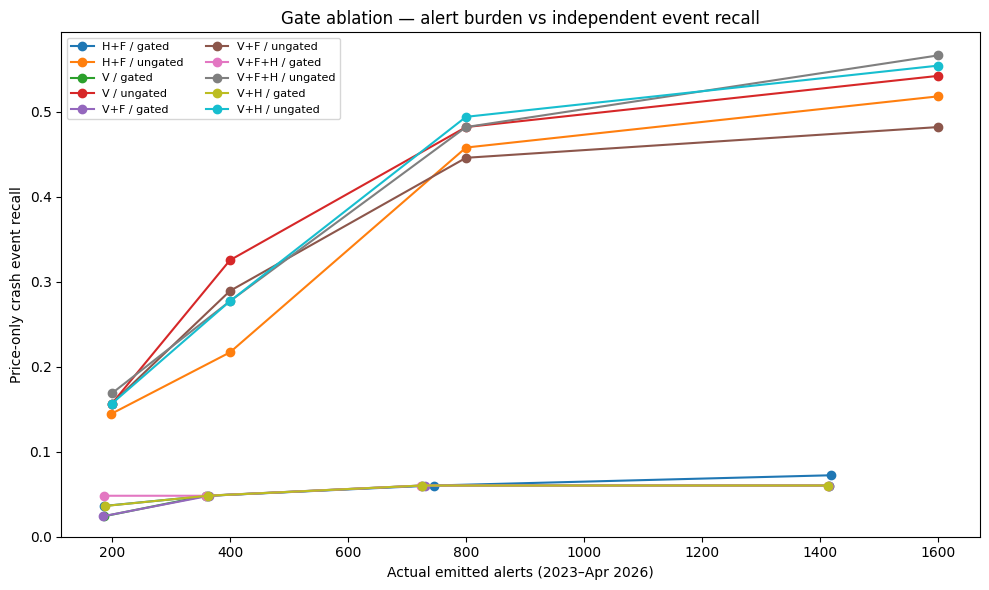

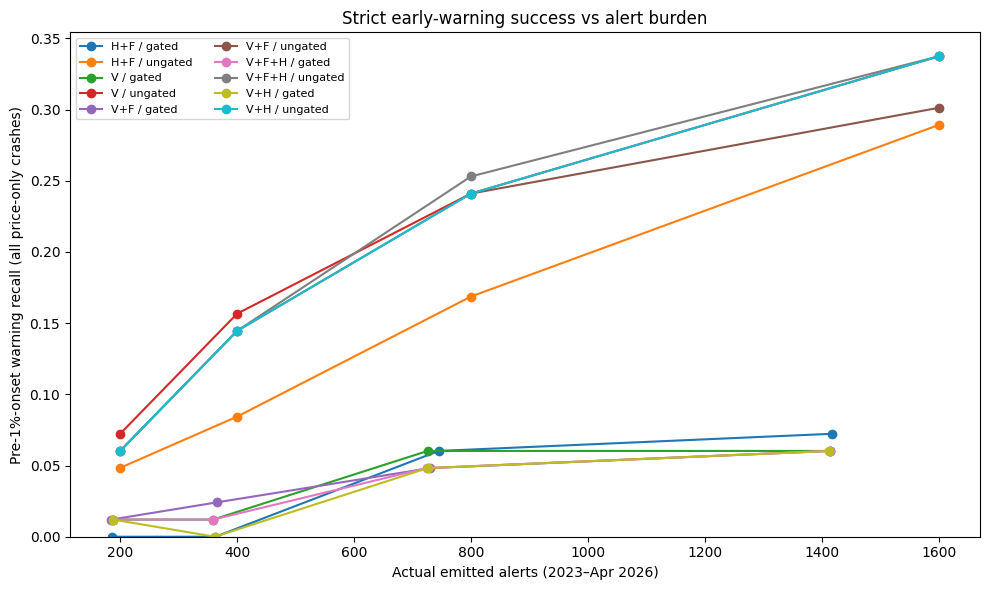

SAVED TO: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/gate_ablation_price_only_v1
 - event_level_pair_table.csv
 - gate_ablation_policy_comparison.csv
 - gate_ablation_pre_onset_tradeoff.png
 - gate_ablation_recall_tradeoff.png
 - matched_price_only_events.csv
 - no_alert_baseline.csv
 - paired_event_gate_and_spectral.csv
 - threshold_calibration_2022.csv


In [6]:
fig,ax=plt.subplots(figsize=(10,6))
for name,g in results.groupby(['model','gate']):
    sub=g.sort_values('alarms')
    ax.plot(sub.alarms,sub.event_recall,'o-',label=' / '.join(name))
ax.set_xlabel('Actual emitted alerts (2023–Apr 2026)')
ax.set_ylabel('Price-only crash event recall')
ax.set_ylim(bottom=0)
ax.legend(ncol=2,fontsize=8)
ax.set_title('Gate ablation — alert burden vs independent event recall')
fig.tight_layout();fig.savefig(OUT/'gate_ablation_recall_tradeoff.png',dpi=160)
plt.show()

fig,ax=plt.subplots(figsize=(10,6))
for name,g in results.groupby(['model','gate']):
    sub=g.sort_values('alarms')
    ax.plot(sub.alarms,sub.pre_onset_recall,'o-',label=' / '.join(name))
ax.set_xlabel('Actual emitted alerts (2023–Apr 2026)')
ax.set_ylabel('Pre-1%-onset warning recall (all price-only crashes)')
ax.set_ylim(bottom=0)
ax.legend(ncol=2,fontsize=8)
ax.set_title('Strict early-warning success vs alert burden')
fig.tight_layout();fig.savefig(OUT/'gate_ablation_pre_onset_tradeoff.png',dpi=160)
plt.show()

print('SAVED TO:',OUT)
for fname in sorted(OUT.glob('*')):print(' -',fname.name)


## Interpretation
- `gate_ablation_policy_comparison.csv` is the primary table: `V+F gated` against `V+F ungated`, and `V+F+H gated` against `V+F+H ungated`, under the same declared target and cap, with the actual alert counts.
- `before_1pct_onset` counts warnings issued before the decline began, as opposed to alerts after the crash had already started.
- In `paired_event_gate_and_spectral.csv`, `add_spectral_to_VF_open` isolates hS with all other conditions and the training target unchanged; paired tests are uncertain when only a few events differ.
- `threshold_calibration_2022.csv` shows whether a gated policy can reach the requested alert budget at all in calibration; an unreachable target does not give a fair equal-count comparison.